In [1]:
%load_ext autoreload
%autoreload 2

In [218]:
import sys
sys.path.append("..")

import ast
import json
from pathlib import Path
import numpy as np
import xarray as xr
import rioxarray as rxr
import pandas as pd
import regionmask
import ibicus
from ibicus.debias import QuantileMapping, ISIMIP

import rasterio
from rasterio.warp import transform

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid", {"grid.color": ".93"})

from src.load_data import ClimateModelData
from src.timesteps_adjustments import extract_adjusted_timesteps, get_new_timesteps

In [3]:
paths = json.load(open("../paths.json"))

path_data_analysis = Path(paths["path_data_analysis"])
path_data_processed = Path(paths["path_data_processed"])
path_data_cordex = Path(paths["path_data_cordex"])
path_data_adjusted_cordex = Path(paths["path_data_adjusted_cordex"])
path_data_cerra = Path(paths["path_data_cerra"])
path_data_cerra_land = Path(paths["path_data_cerra_land"])
path_figs = Path(paths["path_figs"])

# Load climate model data

**CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1** simulation characteristics:
  * atransient aerosols
  * has wind speeds at multiple height levels
  * Lambert conformal conic projection in **km**

In [4]:
climate_model_chain = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1"
climate_scenario = "rcp85"

institute = climate_model_chain.split("-")[0]
rcm = climate_model_chain.split("_")[0]
gcm = climate_model_chain.split("_")[1]
ensemble = climate_model_chain.split("_")[-1]

In [5]:
# wind_vars = ["ua100m", "va100m", "ua150m", "va150m", "ua200m", "va200m"]
# for var in wind_vars:
#     (Path("/landclim/yhaddad/cordex/EUR-11") / climate_scenario / temp_res / var / institute / gcm / rcm / ensemble).mkdir(parents=True, exist_ok=True)
#     (Path("/landclim/yhaddad/cordex/EUR-11") / "historical" / temp_res / var / institute / gcm / rcm / ensemble).mkdir(parents=True, exist_ok=True)

## 1. Load linearized mapping of years to adjust warming trend of EURO-CORDEX model

In [6]:
df_climate_models_mapping = pd.read_csv(path_data_adjusted_cordex / "year_lists.csv")
df_climate_models_mapping["year_list"] = [ast.literal_eval(l) for l in df_climate_models_mapping["year_list"]]

adjusted_timesteps = extract_adjusted_timesteps(df_climate_models_mapping, climate_model_chain, climate_scenario)

## 2. Load climate data

In [51]:
variable = "tas"
temp_res = "3hr"

cordex_var = path_data_cordex / climate_scenario / temp_res / variable / institute / gcm / rcm / ensemble
cordex_var_hist = path_data_cordex / "historical" / temp_res / variable / institute / gcm / rcm / ensemble
cordex_processed_var = path_data_processed / "cordex-processed" / f"{climate_model_chain}_{climate_scenario}" / "raw" / f"{variable}_ch.nc"

In [8]:
rds = xr.open_dataset(list(cordex_var.glob("*"))[0])

In [52]:
climate_data = ClimateModelData(cordex_processed_var, chunks=None, load=True)

In [53]:
climate_data.ds_data

<xarray.Dataset> Size: 2GB
Dimensions:  (time: 318496, lat: 30, lon: 50)
Coordinates:
  * time     (time) datetime64[ns] 3MB 1991-01-01 ... 2099-12-31T21:00:00
  * lon      (lon) float64 400B 5.85 5.95 6.05 6.15 ... 10.45 10.55 10.65 10.75
  * lat      (lat) float64 240B 45.05 45.15 45.25 45.35 ... 47.75 47.85 47.95
    height   (time) float64 3MB 2.0 2.0 2.0 2.0 2.0 ... 10.0 10.0 10.0 10.0 10.0
Data variables:
    tas      (time, lat, lon) float32 2GB 271.3 269.4 268.5 ... 276.8 276.6
Attributes: (12/29)
    CDI:                            Climate Data Interface version 2.2.1 (htt...
    Conventions:                    CF-1.6
    institution:                    CNRM (Centre National de Recherches Meteo...
    description:                    Created by xios
    title:                          Created by xios
    creation_date:                  2018-10-19T08:40:28Z
    ...                             ...
    comment:                        CORDEX Europe EUR-11 CNRM-ALADIN 6.3 L91 ...
    c3s_disclaimer:                 This data has been produced in the contex...
    driving_experiment_comment:     Known issue correction: this simulation (...
    frequency:                      3hr
    history:                        Fri Jan 24 11:42:58 2025: cdo remapcon,/l...
    CDO:                            Climate Data Operators version 2.2.0 (htt...

<Axes: title={'center': 'time = 1991-01-01, height = 2.0 [m]'}, xlabel='longitude [degrees_east]', ylabel='latitude [degrees_north]'>

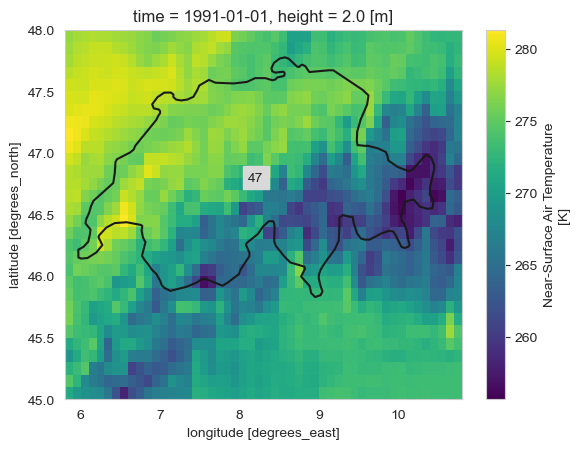

In [54]:
climate_data.ds_data.isel(time=0)['tas'].plot(x='lon', y='lat')

regionmask.defined_regions.natural_earth_v5_0_0.countries_50[['Switzerland']].plot_regions()

In [57]:
climate_data.ds_data

<xarray.Dataset> Size: 2GB
Dimensions:  (time: 318496, lat: 30, lon: 50)
Coordinates:
  * time     (time) datetime64[ns] 3MB 1991-01-01 ... 2099-12-31T21:00:00
  * lon      (lon) float64 400B 5.85 5.95 6.05 6.15 ... 10.45 10.55 10.65 10.75
  * lat      (lat) float64 240B 45.05 45.15 45.25 45.35 ... 47.75 47.85 47.95
    height   (time) float64 3MB 2.0 2.0 2.0 2.0 2.0 ... 10.0 10.0 10.0 10.0 10.0
Data variables:
    tas      (time, lat, lon) float32 2GB 271.3 269.4 268.5 ... 276.8 276.6
Attributes: (12/29)
    CDI:                            Climate Data Interface version 2.2.1 (htt...
    Conventions:                    CF-1.6
    institution:                    CNRM (Centre National de Recherches Meteo...
    description:                    Created by xios
    title:                          Created by xios
    creation_date:                  2018-10-19T08:40:28Z
    ...                             ...
    comment:                        CORDEX Europe EUR-11 CNRM-ALADIN 6.3 L91 ...
    c3s_disclaimer:                 This data has been produced in the contex...
    driving_experiment_comment:     Known issue correction: this simulation (...
    frequency:                      3hr
    history:                        Fri Jan 24 11:42:58 2025: cdo remapcon,/l...
    CDO:                            Climate Data Operators version 2.2.0 (htt...

In [14]:
variables = ["tas", "pr", "rsds", "sfcWind", "huss"]
climate_data_dict = {}

for variable in variables:
    cordex_processed_var = path_data_processed / "cordex-processed" / f"{climate_model_chain}_{climate_scenario}" / "raw" / f"{variable}_ch.nc"
    climate_data_dict[variable] = ClimateModelData(cordex_processed_var, chunks=None, load=True)

## 3. Plot general plots

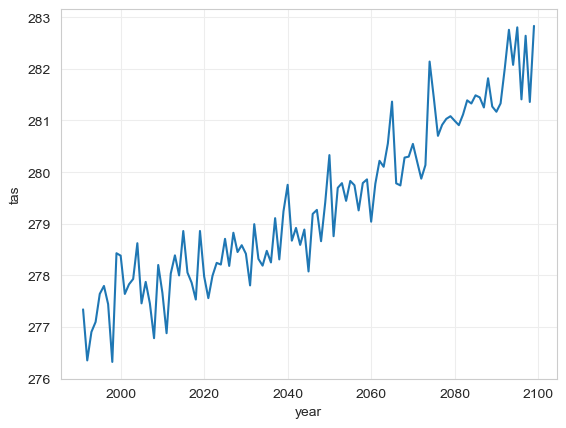

In [88]:
climate_data.plot_annual_mean("tas", spatial_mean=True)

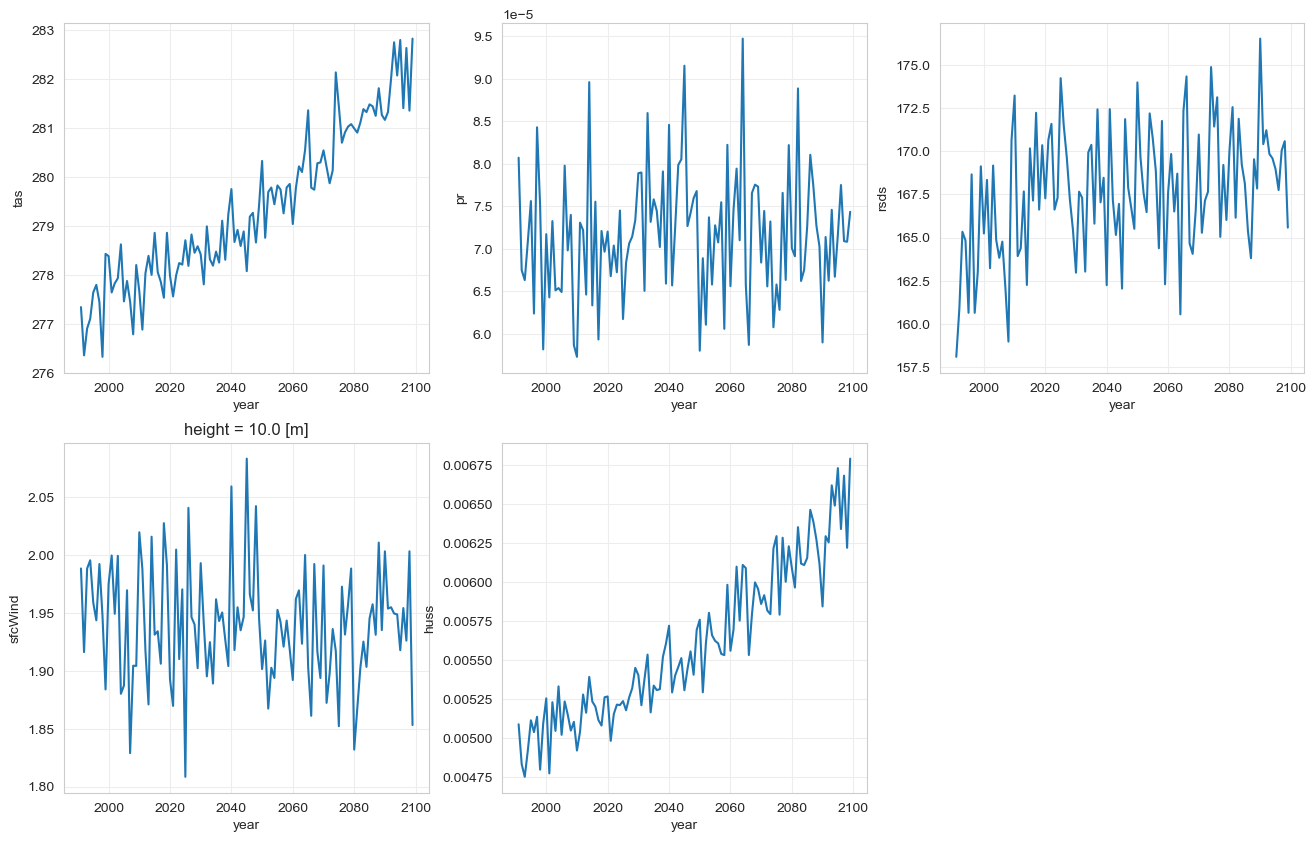

In [91]:
fig, ax = plt.subplots(2, 3, figsize=(16, 10))
ax = ax.flatten()
for i, variable in enumerate(climate_data_dict):
    climate_data_dict[variable].plot_annual_mean(variable, spatial_mean=True, ax=ax[i])

ax[-1].axis("off")
plt.show()

# Load reanalysis data

In [109]:
variable = "tp"
cerra_var = path_data_cerra / "original" / variable

In [123]:
ds_reanalysis_data = xr.open_dataset(cerra_var / "2t_3hr_cerra_1985.nc").sortby("time")

In [124]:
ds_reanalysis_data

<xarray.Dataset> Size: 239GB
Dimensions:  (time: 107616, lat: 507, lon: 1096)
Coordinates:
  * time     (time) datetime64[ns] 861kB 1984-09-01 ... 2021-06-30T21:00:00
  * lon      (lon) float64 9kB -44.55 -44.45 -44.35 -44.25 ... 64.75 64.85 64.95
  * lat      (lat) float64 4kB 21.95 22.05 22.15 22.25 ... 72.35 72.45 72.55
Data variables:
    tp       (time, lat, lon) float32 239GB dask.array<chunksize=(100, 507, 1096), meta=np.ndarray>
Attributes:
    CDI:          Climate Data Interface version 2.2.1 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    history:      Mon Feb 03 17:18:40 2025: cdo remapcon,/landclim/yhaddad/cl...
    CDO:          Climate Data Operators version 2.2.0 (https://mpimet.mpg.de...

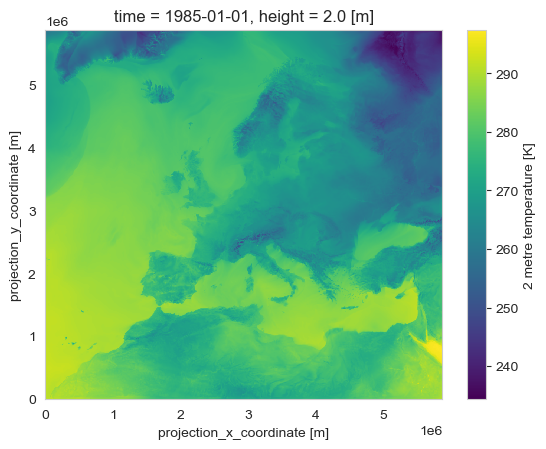

In [18]:
ds_reanalysis_data["2t"].isel(time=0).plot()

# Load regridded climate model and reanalysis data

In [156]:
climate_model_chain = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1"
climate_scenario = "rcp85"
cordex_var = "tas"
regridded_cordex_var_path = path_data_processed / "cordex_processed" / f"{climate_model_chain}_{climate_scenario}" / "regridded"

cerra_var = "2t"
regridded_cerra_var_path = path_data_processed / "cerra_processed" / "regridded"

In [170]:
chunks = {"time": 500, "lat": 256, "lon": 256}
ds_climate_model_data = xr.open_zarr(regridded_cordex_var_path / f"{cordex_var}.zarr").chunk(chunks=chunks)
ds_reanalysis_data = xr.open_zarr(regridded_cerra_var_path / f"{cerra_var}.zarr").chunk(chunks=chunks)

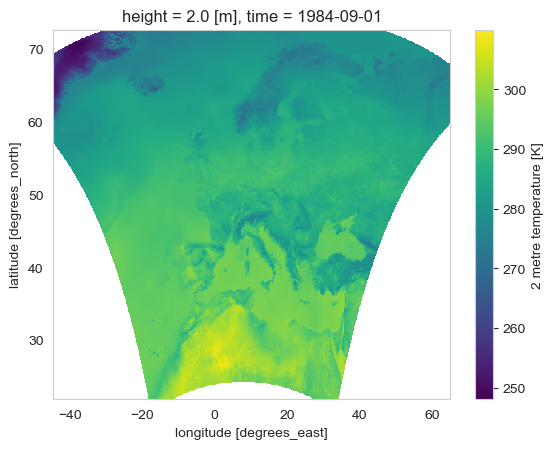

In [158]:
ds_reanalysis_data.isel(time=0)["2t"].plot()

# Debias climate model simulation

In [174]:
zurich_lat = 47.3769
zurich_lon = 8.5417

ds_reanalysis_data_zurich = ds_reanalysis_data.sel(time=slice("1991", "2020")).isel(height=0).sel(lat=zurich_lat, lon=zurich_lon, method="nearest").rename({"lat": "y", "lon": "x"})
ds_climate_model_data_zurich_past = ds_climate_model_data.sel(time=slice("1991", "2020")).sel(lat=zurich_lat, lon=zurich_lon, method="nearest")
ds_climate_model_data_zurich_future = ds_climate_data.sel(time=slice("1991", "2020")).sel(lat=zurich_lat, lon=zurich_lon, method="nearest")

In [195]:
lat_extent = [45.8, 47.9]
lon_extent = [5.9, 10.5]

ds_reanalysis_data_ch = ds_reanalysis_data.sel(time=slice("1991", "2020")).isel(height=0).sel(lat=slice(*lat_extent), lon=slice(*lon_extent)).rename({"lat": "y", "lon": "x"})
ds_climate_model_data_ch_past = ds_climate_model_data.sel(time=slice("1991", "2020")).sel(lat=slice(*lat_extent), lon=slice(*lon_extent)).rename({"lat": "y", "lon": "x"})
ds_climate_model_data_ch_future = ds_climate_model_data.sel(time=slice("2021", None)).sel(lat=slice(*lat_extent), lon=slice(*lon_extent)).rename({"lat": "y", "lon": "x"})

In [196]:
debiaser = QuantileMapping.from_variable("tas")

debiased_cm_future_cerra = debiaser.apply(ds_reanalysis_data_ch.sel(time=ds_reanalysis_data_ch.time.dt.hour == 3)["2t"].values, 
                                          ds_climate_model_data_ch_past.sel(time=ds_climate_model_data_ch_past.time.dt.hour == 3)["tas"].values, 
                                          ds_climate_model_data_ch_future.sel(time=ds_climate_model_data_ch_future.time.dt.hour == 3)["tas"].values)

100%|██████████| 966/966 [00:02<00:00, 373.24it/s]


In [203]:
ds_climate_model_data_ch_future.sel(time=ds_climate_model_data_ch_future.time.dt.hour == 3)

<xarray.Dataset> Size: 112MB
Dimensions:  (time: 28854, y: 21, x: 46)
Coordinates:
    height   (time) float64 231kB dask.array<chunksize=(42,), meta=np.ndarray>
  * y        (y) float64 168B 45.85 45.95 46.05 46.15 ... 47.65 47.75 47.85
  * x        (x) float64 368B 5.95 6.05 6.15 6.25 ... 10.15 10.25 10.35 10.45
  * time     (time) datetime64[ns] 231kB 2021-01-01T03:00:00 ... 2099-12-31T0...
Data variables:
    tas      (time, y, x) float32 111MB dask.array<chunksize=(42, 17, 7), meta=np.ndarray>
Attributes: (12/29)
    CDI:                            Climate Data Interface version 2.2.1 (htt...
    CDO:                            Climate Data Operators version 2.2.0 (htt...
    CORDEX_domain:                  EUR-11
    Convention:                     CF-1.6
    Conventions:                    CF-1.6
    c3s_disclaimer:                 This data has been produced in the contex...
    ...                             ...
    product:                        output
    project_id:                     CORDEX
    rcm_version_id:                 v2
    references:                     http://www.umr-cnrm.fr/spip.php?article12...
    title:                          Created by xios
    tracking_id:                    hdl:21.14103/b5f438d4-cd97-40cf-b3d7-6c05...

In [212]:
ds_climate_model_data_ch_future_debiased = ds_climate_model_data_ch_future.sel(time=ds_climate_model_data_ch_future.time.dt.hour == 3).copy()
ds_climate_model_data_ch_future_debiased["tas"] = (["time", "y", "x"], debiased_cm_future_cerra)

In [213]:
ds_climate_model_data_ch_future_debiased

<xarray.Dataset> Size: 112MB
Dimensions:  (time: 28854, y: 21, x: 46)
Coordinates:
    height   (time) float64 231kB dask.array<chunksize=(42,), meta=np.ndarray>
  * y        (y) float64 168B 45.85 45.95 46.05 46.15 ... 47.65 47.75 47.85
  * x        (x) float64 368B 5.95 6.05 6.15 6.25 ... 10.15 10.25 10.35 10.45
  * time     (time) datetime64[ns] 231kB 2021-01-01T03:00:00 ... 2099-12-31T0...
Data variables:
    tas      (time, y, x) float32 111MB 275.6 275.1 275.2 ... 279.9 279.7 279.4
Attributes: (12/29)
    CDI:                            Climate Data Interface version 2.2.1 (htt...
    CDO:                            Climate Data Operators version 2.2.0 (htt...
    CORDEX_domain:                  EUR-11
    Convention:                     CF-1.6
    Conventions:                    CF-1.6
    c3s_disclaimer:                 This data has been produced in the contex...
    ...                             ...
    product:                        output
    project_id:                     CORDEX
    rcm_version_id:                 v2
    references:                     http://www.umr-cnrm.fr/spip.php?article12...
    title:                          Created by xios
    tracking_id:                    hdl:21.14103/b5f438d4-cd97-40cf-b3d7-6c05...

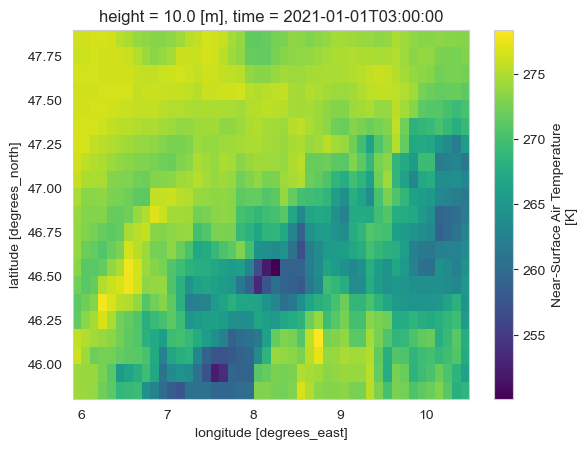

In [214]:
ds_climate_model_data_ch_future.sel(time=ds_climate_model_data_ch_future.time.dt.hour == 3).isel(time=0).tas.plot()

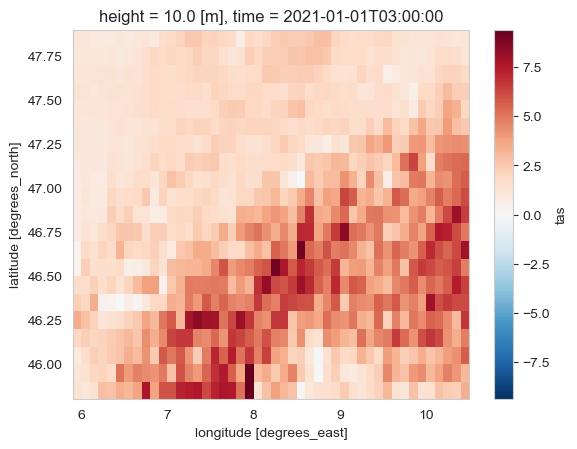

In [216]:
(ds_climate_model_data_ch_future_debiased.isel(time=0) - ds_climate_model_data_ch_future.sel(time=ds_climate_model_data_ch_future.time.dt.hour == 3).isel(time=0)).tas.plot()

In [220]:
debiaser_qm = QuantileMapping()

debiased_cm_future_cerra_qm = debiaser_qm.apply(ds_reanalysis_data_ch.sel(time=ds_reanalysis_data_ch.time.dt.hour == 3)["2t"].values, 
                                          ds_climate_model_data_ch_past.sel(time=ds_climate_model_data_ch_past.time.dt.hour == 3)["tas"].values, 
                                          ds_climate_model_data_ch_future.sel(time=ds_climate_model_data_ch_future.time.dt.hour == 3)["tas"].values)

100%|██████████| 966/966 [00:03<00:00, 292.51it/s]


In [225]:
tas_debiaser_ISIMIP = ISIMIP.from_variable("tas")

debiased_cm_future_cerra_ISIMIP = tas_debiaser_ISIMIP.apply(ds_reanalysis_data_ch.sel(time=ds_reanalysis_data_ch.time.dt.hour == 3)["2t"].values, 
                                          ds_climate_model_data_ch_past.sel(time=ds_climate_model_data_ch_past.time.dt.hour == 3)["tas"].values, 
                                          ds_climate_model_data_ch_future.sel(time=ds_climate_model_data_ch_future.time.dt.hour == 3)["tas"].values)

  0%|          | 0/966 [00:00<?, ?it/s]/home/yhaddad/.conda/envs/bias_correction_2023/lib/python3.11/site-packages/ibicus/debias/_debiaser.py:387: UserWarning: ISIMIP runs without time-information for at least one of obs, cm_hist or cm_future.
                    This information is inferred, assuming the first observation is on a January 1st. Observations are chunked according to the assumed time information.
                    This might lead to slight numerical differences to the run with time information, however the debiasing is not fundamentally changed.
  return func(obs, cm_hist, cm_future, **kwargs)
100%|██████████| 966/966 [1:17:28<00:00,  4.81s/it]


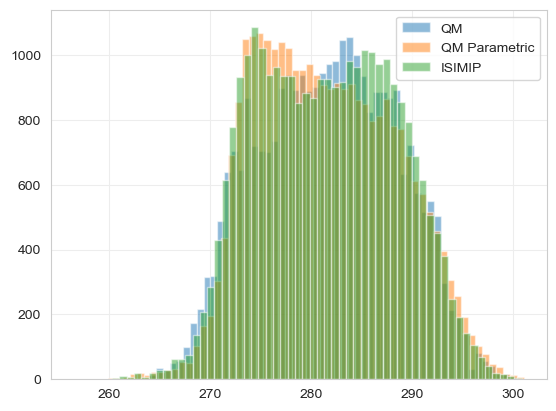

In [226]:
plt.hist(debiased_cm_future_cerra_qm[:, 1, 1], bins="auto", alpha = 0.5, label = "QM")
plt.hist(debiased_cm_future_cerra[:, 1, 1], bins="auto", alpha = 0.5, label = "QM Parametric")
plt.hist(debiased_cm_future_cerra_ISIMIP[:, 1, 1], bins="auto", alpha = 0.5, label = "ISIMIP")
plt.legend()
plt.show()